In [1]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
from pprint import pformat
import pickle

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [2]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics

In [3]:
# Define the filter criteria
filter_criteria = {
    #'config.image_encoder.use': True,
    #'config.tabular_encoder.use': True,
    #'config.loc_encoder.use': True,
    

    "group" : "27/9 modalities ",
    #"group" : "18/9 modalities",
    #"group" : "11/9 loc encoders",

    #"config.seed" : 420,
    #"$and": [{
    #'created_at': {
    #        "$lt": '2024-06-24T00',
    #        "$gt": '2024-06-01T17'
    #    }
    #}]

    
}





In [4]:
models = utils.get_wandb_runs(filter_criteria)

print(f'models: {len(models)}')

models: 245


In [5]:
'''
In some cases, the wandb API filtering doesn't work;
If I get 0 models returned, I need to 
    1. remove the problematic filter
    2. get all the runs
    3. filter manually as below
'''
#Example:
#models = [model for model in models  if model['config']['seed'] == 422]  
#models = [model for model in models  if model['config']['train_dst_size'] == 10000]  
#models = [model for model in models  if model['config']['image_encoder']['use']]  
#models = [model for model in models  if model['config']['image_encoder']['use']]  
#print(len(selected_models))
#models = selected_models

"\nIn some cases, the wandb API filtering doesn't work;\nIf I get 0 models returned, I need to \n    1. remove the problematic filter\n    2. get all the runs\n    3. filter manually as below\n"

In [6]:
print(len(models))

245


In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 11


In [8]:
"""CHECKPOINT_TYPE = 'last'

for i, model_dict in enumerate(tqdm.tqdm(models)):
    #if i < 42:
    #    continue
    #if i > 2:
    #    break
    
    #This is just to get rid of wandb objects that are un-picklable wtf
    model_dict['summary'] = None
    
    try:
        metrics, preds = utils.load_model_and_predict(model_dict, n_classes, device, 'val', CHECKPOINT_TYPE)
    except Exception as e:
        print(e)
        continue
    model_dict['predictions'] = preds
    model_dict['metrics'] = metrics
    
    #try:
    #    model_dict['summary']['_wandb'] = dict(model_dict['summary']['_wandb'])
    #    model_dict['summary']['val conf matrix'] = None
    #    model_dict['summary']['train conf matrix'] = None
    #except KeyError:
    #    pass
    """

"CHECKPOINT_TYPE = 'last'\n\nfor i, model_dict in enumerate(tqdm.tqdm(models)):\n    #if i < 42:\n    #    continue\n    #if i > 2:\n    #    break\n    \n    #This is just to get rid of wandb objects that are un-picklable wtf\n    model_dict['summary'] = None\n    \n    try:\n        metrics, preds = utils.load_model_and_predict(model_dict, n_classes, device, 'val', CHECKPOINT_TYPE)\n    except Exception as e:\n        print(e)\n        continue\n    model_dict['predictions'] = preds\n    model_dict['metrics'] = metrics\n    \n    #try:\n    #    model_dict['summary']['_wandb'] = dict(model_dict['summary']['_wandb'])\n    #    model_dict['summary']['val conf matrix'] = None\n    #    model_dict['summary']['train conf matrix'] = None\n    #except KeyError:\n    #    pass\n    "

In [9]:
##### selected_models = [model for model in models  if model['config']['train_examples_per_class'] < 1000]  


In [8]:
def inspect_objects(d, path=""):
    if isinstance(d, dict):
        for k, v in d.items():
            new_path = f"{path}/{k}" if path else str(k)
            inspect_objects(v, new_path)
    elif isinstance(d, list):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    elif isinstance(d, tuple):
        for i, item in enumerate(d):
            new_path = f"{path}/{i}"
            inspect_objects(item, new_path)
    else:
        print(f"Object at path {path}: {type(d)}")

In [11]:

#filename = '26_7_eval_on_test_set'

#filename = '29_7_eval_on_test_set'
#filename_2 = '30_7_eval_on_test_set'
#filename = '30_7_eval_on_test_set_seed_422to425'
#filename = '5_8_eval_on_test_set_one_img'
#filename = '8_8_eval_on_test_set_one_img'
#filename = '9_8_eval_on_test_set_one_img'
#filename = '9_8_eval_on_test_set_four_img'
filename = '27_9_modalities'


In [12]:
"""with open(f'{filename}.pickle', 'wb') as handle:
    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)
    
    with open('27_9_modalities_backup.pickle', 'wb') as handle:
    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)"""

"with open(f'{filename}.pickle', 'wb') as handle:\n    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)\n    \n    with open('27_9_modalities_backup.pickle', 'wb') as handle:\n    pickle.dump(models, handle, protocol=pickle.HIGHEST_PROTOCOL)"

In [8]:


with open(f'27_9_modalities_backup.pickle', 'rb') as handle:
    other_models = pickle.load(handle)


In [9]:
models = other_models 

In [10]:
#models = [model for model in other_models  if model['config']['two_model_regularization']['use'] == False]
#models = [model for model in models  if model['config']['model_version'] == 'v1']




In [11]:
models_ = [model for model in other_models if model['config'] != {}]
models__ = [model for model in models_ if 'metrics' in model.keys()]


In [12]:
len(models__)

245

In [13]:
hyperparams_values = utils.find_keys_with_multiple_values([model['config'] for model in models])

In [14]:
hyperparams_values

{'seed': [420, 422, 423, 424, 425],
 'loc_encoder': {'use': [False, True]},
 'image_encoder': {'use': [False, True]},
 'tabular_encoder': {'use': [False, True]},
 'train_dataset_total_size': [100, 1000, 5000, 200, 10000, 2000, 500]}

In [15]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv")
labels = labels.loc[labels['split'] == 4].reset_index(drop=True) # Get test examples 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()


In [16]:
def get_models_with_config(_models, target_config):
    
    def has_key_value_pair(d, target):
        if isinstance(d, dict) and isinstance(target, dict):
            for key, value in target.items():
                if key in d:
                    if isinstance(value, dict) and isinstance(d[key], dict):
                        if not has_key_value_pair(d[key], value):
                            return False
                    else:
                        if d[key] != value:
                            return False
                else:
                    return False
            return True
        return d == target
    
    models_with_this_config_combination = []
    for model in _models:
        skip_model = False
        for key in target_config.keys():
            if not has_key_value_pair(model['config'][key],target_config[key]):
            #if model['config'][key] != target_config[key]:
                skip_model = True
                break
        if skip_model:
            continue
        models_with_this_config_combination.append(model)
    
    return models_with_this_config_combination

In [17]:
exclude_keys = ['seed']

combinations = utils.generate_combinations(hyperparams_values, exclude_keys)

In [18]:
#This I need to do in case there is only 1 seed
#hyperparams_values['seed'] = [420]

In [19]:

performance_per_configuration = {}

for combo in combinations:
    
    metrics_per_random_seed = []
    combo_str = ' '.join(pformat(combo, width=1).split())
    #print(combo_str)

    #Compute metrics per each random seed separately
    for seed in hyperparams_values['seed']:
        combo['seed'] = seed 
        
        #Get all models that have the configuration setup 
        model_with_this_config = get_models_with_config(models, combo)
        if not model_with_this_config:
            continue

            
        assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"
        model_with_this_config = model_with_this_config[0]
        if not 'metrics' in model_with_this_config.keys():
            continue
            
            
        metrics_per_random_seed.append(pd.DataFrame(model_with_this_config['metrics']))


    if not metrics_per_random_seed:
        print("no metrics for: ", combo)
        continue


    # Concatenate DataFrames along a new axis
    concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

    # Compute the mean along the new axis
    mean_df = concat_df.groupby(level=1).mean()

    # Compute the standard deviation along the new axis
    std_df = concat_df.groupby(level=1).std()   
    
    

    performance_per_configuration[combo_str] = {}
    performance_per_configuration[combo_str]['mean'] = mean_df
    performance_per_configuration[combo_str]['std'] = std_df



        

no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 100, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 1000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 5000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 200, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 2000, 'seed': 425}
no metrics for:  

In [20]:
#performance_per_configuration = {key:value for key, value in performance_per_configuration.items() if "{'model_version': 'v2', 'tabular_encoder': {'use': False}" not in key}


In [21]:
models_100_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 100}" in key}
models_200_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 200}" in key}
models_500_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 500}" in key}
models_1000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 1000}" in key}
models_2000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 2000}" in key}
models_5000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 5000}" in key}
models_10000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 10000}" in key}
#models_20000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 20000}" in key}


In [22]:
def plot_metrics(metrics, metric='accuracy', ylim=(0.2, 1.2) ):
    
    #class_names = list(LABEL_MAPPING.keys())
    class_names = ['weighted avg', 'macro avg']
    class_names.append(metric)
    stats = {}
    for model_name, model_stats in metrics.items():
        stats[model_name] = {}
        for cls in class_names:
            stats[model_name][cls] = {}
            stats[model_name][cls]['score'] = metrics[model_name]['mean'][cls]['f1-score']
            stats[model_name][cls]['std'] = metrics[model_name]['std'][cls]['f1-score']

    # Initialize plot
    fig, ax = plt.subplots(figsize=(12, 6))

    # Set the width of the bars
    bar_width = 0.7/len(metrics)

    # Set positions of the bars on the x-axis
    index = np.arange(len(class_names))

    # Plot each model's data

    #for i, model in enumerate(stats.keys()):
    for i, model in enumerate(list(metrics.keys())): #only models with image
        scores = [stats[model][cls]['score'] for cls in class_names]
        stds = [stats[model][cls]['std'] for cls in class_names]
        ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

    # Set labels, title, and legend
    #ax.set_xlabel('Class')
    #ax.set_ylabel('Score')
    plt.ylim(bottom=ylim[0])
    plt.ylim(top=ylim[1])
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    #ax.legend()

    # Show plot
    plt.tight_layout()
    plt.show(
    )

In [23]:
import ast
import re


# Function to remove 'seed' key-value pairs from a string representation of a dictionary
def remove_seed(entry):
    # Remove the seed key-value pair using regular expressions
    cleaned_entry = re.sub(r"'seed': \d+,? ?", "", entry)
    return cleaned_entry

In [24]:
performance_per_configuration_renamed = {}

for key, value in performance_per_configuration.items():
    performance_per_configuration_renamed[remove_seed(key)] = value
    

In [36]:
def process_stats_all(___models, metric='accuracy', n_examples_list=[200, 500, 1000, 2000, 5000, 10000, 20000]):

    _models_stats = {}
    
    keys_to_delete = []

    _models_stats["{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    
    #_models_stats["{'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    #_models_stats["{'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}

    for n_examples in n_examples_list:

        #for key in _models.keys():
        selected_models = {key:value for key, value in ___models.items() if f"'train_dataset_total_size': {n_examples}}}" in key}
        for key in _models_stats.keys():
            model_name = key.replace("xx", f"'train_dataset_total_size': {n_examples}") 
            try:
                sel_model = selected_models[model_name]
            except KeyError:
                keys_to_delete.append(key)
                continue
            acc = sel_model['mean'][metric]['f1-score']
            std = sel_model['std'][metric]['f1-score']
            _models_stats[key]['acc'].append(acc)
            _models_stats[key]['std'].append(std)

    for key in list(set(keys_to_delete)):
        del _models_stats[key]
        
    return _models_stats
    

In [37]:
#_models_stats_reg = process_stats_reg(reg_models)
#_models_stats_all = process_stats_all(performance_per_configuration_renamed)
#_models_f1 = process_stats_all(performance_per_configuration_renamed, 'macro avg')



In [38]:


run_names_mapping = {
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "loc",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "tab",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "loc+tab",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}" : "image",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "image + location",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "image + tabular",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "image + location + tabular"
}

In [39]:

def _plot_dict(_dict, x_axis_vals, names=run_names_mapping):
    for key, value in _dict.items():
        acc = value['acc']
        std = value['std']
        plt.errorbar(x_axis_vals, acc, yerr=std, label=names[key], capsize=5)

    plt.xlabel('Training dataset size')
    plt.ylabel('Accuracy')
    plt.title('Modality comparison')
    plt.legend(bbox_to_anchor=(1.,1))
    plt.xscale('log')
    plt.grid(True)
    plt.show()

In [40]:


run_names_mapping = {
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "location",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "tabular",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "location + tabular",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}" : "image",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "image + location",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "image + tabular",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "image + location + tabular"
}

In [41]:
'''x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]

for key, value in processed_stats.items():
    if not "'image_encoder': {'use': True}" in key:
        continue
    
    acc = value['acc']
    std = value['std']

    plt.plot(x_axis_vals, acc, label=run_names_mapping[key])
    plt.fill_between(x_axis_vals, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1)

#plt.xticks(x_indices, x_axis_vals)  # Set x-axis ticks to the original x_axis_vals
plt.xlabel('Training dataset size')
plt.ylabel('Accuracy')
#plt.title('Modality comparison')
#plt.legend(bbox_to_anchor=(0.4,0.22), title="Input modalities", fancybox=True, ncol=2, loc="lower left")
plt.legend(bbox_to_anchor=(0.05,1),framealpha=1,  title="Input modalities",  ncol=2, loc="lower left")
plt.xscale('log')
plt.grid(True)
plt.ylim(0.4, 0.9)
plt.xlim(197, 10010)
plt.show()
#plt.savefig('../paper/modality_comparison_with_img_only.png', dpi=200, bbox_inches='tight')'''

'x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]\n\nfor key, value in processed_stats.items():\n    if not "\'image_encoder\': {\'use\': True}" in key:\n        continue\n    \n    acc = value[\'acc\']\n    std = value[\'std\']\n\n    plt.plot(x_axis_vals, acc, label=run_names_mapping[key])\n    plt.fill_between(x_axis_vals, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1)\n\n#plt.xticks(x_indices, x_axis_vals)  # Set x-axis ticks to the original x_axis_vals\nplt.xlabel(\'Training dataset size\')\nplt.ylabel(\'Accuracy\')\n#plt.title(\'Modality comparison\')\n#plt.legend(bbox_to_anchor=(0.4,0.22), title="Input modalities", fancybox=True, ncol=2, loc="lower left")\nplt.legend(bbox_to_anchor=(0.05,1),framealpha=1,  title="Input modalities",  ncol=2, loc="lower left")\nplt.xscale(\'log\')\nplt.grid(True)\nplt.ylim(0.4, 0.9)\nplt.xlim(197, 10010)\nplt.show()\n#plt.savefig(\'../paper/modality_comparison_with_img_only.png\', dpi=200, bbox_inches=\'tight\')'

##  Final figure


### Instead of log scale, set x-ticks manually

In [3]:
processed_stats = process_stats_all(performance_per_configuration_renamed, 'accuracy', n_examples_list=[200, 500, 1000, 2000, 5000, 10000])


NameError: name 'process_stats_all' is not defined

In [43]:
def reorder_dict(original_dict, key_order):
    return {key: original_dict[key] for key in key_order if key in original_dict}


In [44]:
import pprint
pprint.pprint(list(processed_stats.keys()))

["{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, "
 "'tabular_encoder': {'use': False}, xx}",
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, "
 "'tabular_encoder': {'use': True}, xx}",
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, "
 "'tabular_encoder': {'use': True}, xx}",
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, "
 "'tabular_encoder': {'use': False}, xx}",
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, "
 "'tabular_encoder': {'use': False}, xx}",
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, "
 "'tabular_encoder': {'use': True}, xx}",
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, "
 "'tabular_encoder': {'use': True}, xx}"]


In [45]:
new_order = [
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, "
 "'tabular_encoder': {'use': True}, xx}",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, "
 "'tabular_encoder': {'use': False}, xx}",
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, "
 "'tabular_encoder': {'use': True}, xx}",
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, "
 "'tabular_encoder': {'use': False}, xx}",
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, "
 "'tabular_encoder': {'use': True}, xx}",
"{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, "
 "'tabular_encoder': {'use': False}, xx}",
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, "
 "'tabular_encoder': {'use': True}, xx}"
            ]

In [46]:
processed_stats = reorder_dict(processed_stats, new_order)

(0.0, 5.0)

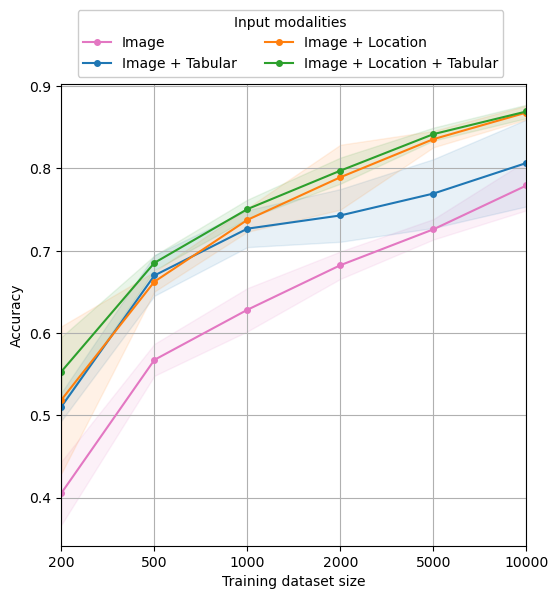

In [47]:
x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]
x_indices = range(len(x_axis_vals)) 


plt.figure(figsize=(6, 6))  # Specify the figure size (width, height)


#colors = ['tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:blue', 'tab:orange', 'tab:green',]
colors = ['tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:blue', 'tab:orange', 'tab:green',]

for i, (key, value) in enumerate(processed_stats.items()):
    if not "'image_encoder': {'use': True}" in key:
        continue
    
    acc = value['acc']
    std = value['std']
    #if not "'image_encoder': {'use': True}" in key:
    #    continue
    plt.plot(x_indices, acc, marker='o',markersize=4, label=run_names_mapping[key].title(), color=colors[i])
    plt.fill_between(x_indices, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1, color=colors[i])

plt.xticks(x_indices, x_axis_vals)  # Map ticks to equally spaced indices
plt.xlabel('Training dataset size')
plt.ylabel('Accuracy')

plt.legend(bbox_to_anchor=(0.02,1), framealpha=1, title="Input modalities", ncol=2, loc="lower left")
plt.grid(True)
#plt.ylim(0.3, 0.9)
plt.xlim(0, len(x_indices)-1 )  # Adjust to fit x_indices range
#plt.show()
#plt.savefig('../paper/modality_comparison_img_models_only.png', dpi=200, bbox_inches='tight')

In [4]:

run_names_mapping = {
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "location",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "tabular",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "location + tabular",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}" : "image",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "image + location",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "image + tabular",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "image + location\n + tabular"
}

In [5]:
processed_stats =  {"{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}": {'acc': [0.3843533123028391,
   0.44143007360672976,
   0.45535226077812824,
   0.4134174553101998,
   0.46418506834910617,
   0.4410935856992639],
  'std': [0.1147714631440405,
   0.08113533597217987,
   0.08863690939250116,
   0.03760032409697728,
   0.05787521702553927,
   0.07282575018414102]},
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}": {'acc': [0.5591587802313354,
   0.49261829652996847,
   0.5300525762355416,
   0.550578338590957,
   0.5370767613038907,
   0.5695057833859096],
  'std': [0.049568522425846286,
   0.10972685297822203,
   0.013978240364247172,
   0.021695072511981123,
   0.023636348249285934,
   0.03803264725623601]},
 "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}": {'acc': [0.4709568874868559,
   0.5501997896950578,
   0.53863301787592,
   0.5613880126182965,
   0.5985699263932702,
   0.6190115667718191],
  'std': [0.10975788537724329,
   0.022161192000274475,
   0.03634486822231542,
   0.03597155225901845,
   0.021319984412718106,
   0.01075807937565357]},
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}": {'acc': [0.40567823343848575,
   0.5674868559411147,
   0.6283491062039958,
   0.6825236593059937,
   0.726098843322818,
   0.779348054679285],
  'std': [0.03849758198947078,
   0.019355253998214687,
   0.026283238243247176,
   0.016658355227071424,
   0.012428114641782046,
   0.03017469205420457]},
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}": {'acc': [0.5107045215562566,
   0.670031545741325,
   0.7268980021030493,
   0.7429652996845426,
   0.7695478443743429,
   0.8066876971608833],
  'std': [0.017075932495828405,
   0.024668509746972444,
   0.02245619589062235,
   0.032039390241777016,
   0.041809288956640774,
   0.05276797843734449]},
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}": {'acc': [0.5189484752891693,
   0.662502628811777,
   0.7375814931650894,
   0.7894006309148265,
   0.8356677181913774,
   0.8679705573080968],
  'std': [0.08936903506553277,
   0.012054895018039734,
   0.014434948852597444,
   0.03944902549254355,
   0.00991181270667515,
   0.008462520354967303]},
 "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}": {'acc': [0.5533123028391167,
   0.6853838065194532,
   0.7506624605678234,
   0.7973922187171398,
   0.8417665615141956,
   0.8692744479495268],
  'std': [0.0420349551400918,
   0.008942288801459225,
   0.01147039477294851,
   0.015851608588168312,
   0.007866922934744922,
   0.008216170268808526]}}

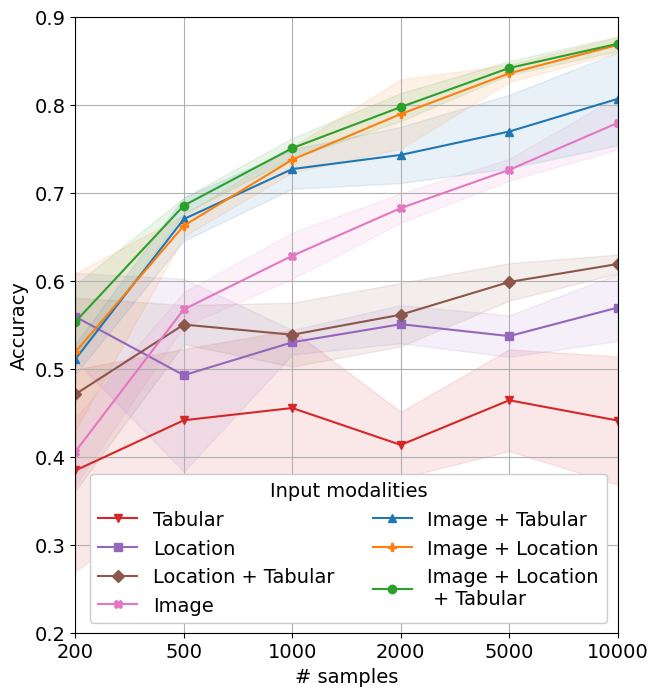

In [16]:
x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]
x_indices = range(len(x_axis_vals)) 


plt.figure(figsize=(7, 8))  # Specify the figure size (width, height)


colors = ['tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:blue', 'tab:orange', 'tab:green',]
markers = ['v', 's', 'D', 'X', '^', 'P', "o"]

for i, (key, value) in enumerate(processed_stats.items()):
    #if not "'image_encoder': {'use': True}" in key:
    #    continue
    
    acc = value['acc']
    std = value['std']
    #if not "'image_encoder': {'use': True}" in key:
    #    continue
    plt.plot(x_indices, acc, marker=markers[i], markersize=6, label=run_names_mapping[key].title(), color=colors[i])
    plt.fill_between(x_indices, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1, color=colors[i])

plt.xticks(x_indices, x_axis_vals)  # Map ticks to equally spaced indices
plt.xlabel('# samples', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)

"""font = {'family' : '',
        'weight' : 'bold',
        'size'   : 12}

plt.suptitle('test title', fontsize=12)
plt.xlabel('xlabel', fontsize=12)
plt.ylabel('ylabel', fontsize=12)

plt.rc('font', **font)"""

plt.rc('font', **{'size'   : 14})



plt.legend(bbox_to_anchor=(0.01,0), framealpha=1, title="Input modalities", ncol=2, loc="lower left")
plt.grid(True)
plt.ylim(0.2, 0.9)
plt.xlim(0, len(x_indices)-1 )  # Adjust to fit x_indices range
#plt.show()
plt.savefig('../paper/LPS_modality_comparison_v2.png', dpi=200, bbox_inches='tight')


In [ ]:
x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]
x_indices = range(len(x_axis_vals)) 


plt.figure(figsize=(6, 8))  # Specify the figure size (width, height)


colors = ['tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:blue', 'tab:orange', 'tab:green',]
markers = ['v', 's', 'D', 'X', '^', 'P', "o"]

for i, (key, value) in enumerate(processed_stats.items()):
    #if not "'image_encoder': {'use': True}" in key:
    #    continue
    
    acc = value['acc']
    std = value['std']
    #if not "'image_encoder': {'use': True}" in key:
    #    continue
    plt.plot(x_indices, acc, marker=markers[i], markersize=6, label=run_names_mapping[key].title(), color=colors[i])
    plt.fill_between(x_indices, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1, color=colors[i])

plt.xticks(x_indices, x_axis_vals)  # Map ticks to equally spaced indices
plt.xlabel('# samples')
plt.ylabel('Accuracy')

#plt.rc('font', **font)

plt.legend(bbox_to_anchor=(0.02,1), framealpha=1, title="Input modalities", ncol=2, loc="lower left")
plt.grid(True)
plt.ylim(0.3, 0.9)
plt.xlim(0, len(x_indices)-1 )  # Adjust to fit x_indices range
plt.show()
#plt.savefig('../paper/modality_comparison_v2.png', dpi=200, bbox_inches='tight')


In [57]:
!pwd

/home/jan/Documents/EPFL/project_2/notebooks


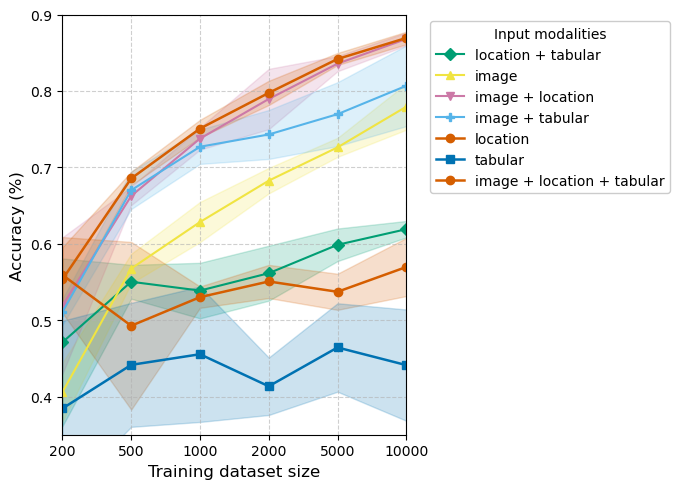

In [36]:
# Dynamically create colors and markers for the exact number of items
num_items = len(processed_stats)
base_colors = ['#D55E00', '#0072B2', '#009E73', '#F0E442', '#CC79A7', '#56B4E9']
base_markers = ['o', 's', 'D', '^', 'v', 'P', ""]

# Extend colors and markers to match the number of items
colors = (base_colors * (num_items // len(base_colors) + 1))[:num_items]
markers = (base_markers * (num_items // len(base_markers) + 1))[:num_items]

priority_colors = ['#0072B2', '#D55E00']  # Cyan and orange equivalents as priority

plt.figure(figsize=(7, 5))  # Adjusted aspect ratio for balance

# Plot non-priority items first
for i, (key, value) in enumerate(processed_stats.items()):
    if colors[i] not in priority_colors:
        acc = value['acc']
        std = value['std']

        plt.plot(
            x_indices,
            acc,
            marker=markers[i],
            markersize=6,
            label=run_names_mapping[key],
            color=colors[i],
            linewidth=1.5  # Thicker lines for better visibility
        )
        plt.fill_between(
            x_indices,
            [a - s for a, s in zip(acc, std)],
            [a + s for a, s in zip(acc, std)],
            alpha=0.2,  # Clearer transparency for the standard deviation
            color=colors[i]
        )

# Plot priority items next
for i, (key, value) in enumerate(processed_stats.items()):
    if colors[i] in priority_colors:
        acc = value['acc']
        std = value['std']

        plt.plot(
            x_indices,
            acc,
            marker=markers[i],
            markersize=6,
            label=run_names_mapping[key],
            color=colors[i],
            linewidth=1.8  # Slightly thicker for priority lines
        )
        plt.fill_between(
            x_indices,
            [a - s for a, s in zip(acc, std)],
            [a + s for a, s in zip(acc, std)],
            alpha=0.2,
            color=colors[i]
        )

# Axis labels
plt.xticks(x_indices, x_axis_vals, fontsize=10)
plt.xlabel('Training dataset size', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)

# Improved legend placement and gridlines
plt.legend(bbox_to_anchor=(1.05, 1), framealpha=1, title="Input modalities", ncol=1, loc="upper left", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

# Adjusted limits for better presentation
plt.ylim(0.35, 0.9)
plt.xlim(0, len(x_indices) - 1)

plt.tight_layout()  # Ensure no clipping of elements
plt.savefig('../paper/modality_comparison_updated.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
print('s')

### Alternative to per-class metrics table

- maybe having these plots per-class (over different training datasets) would be a good idea since I want to highlight the low-data regime performance

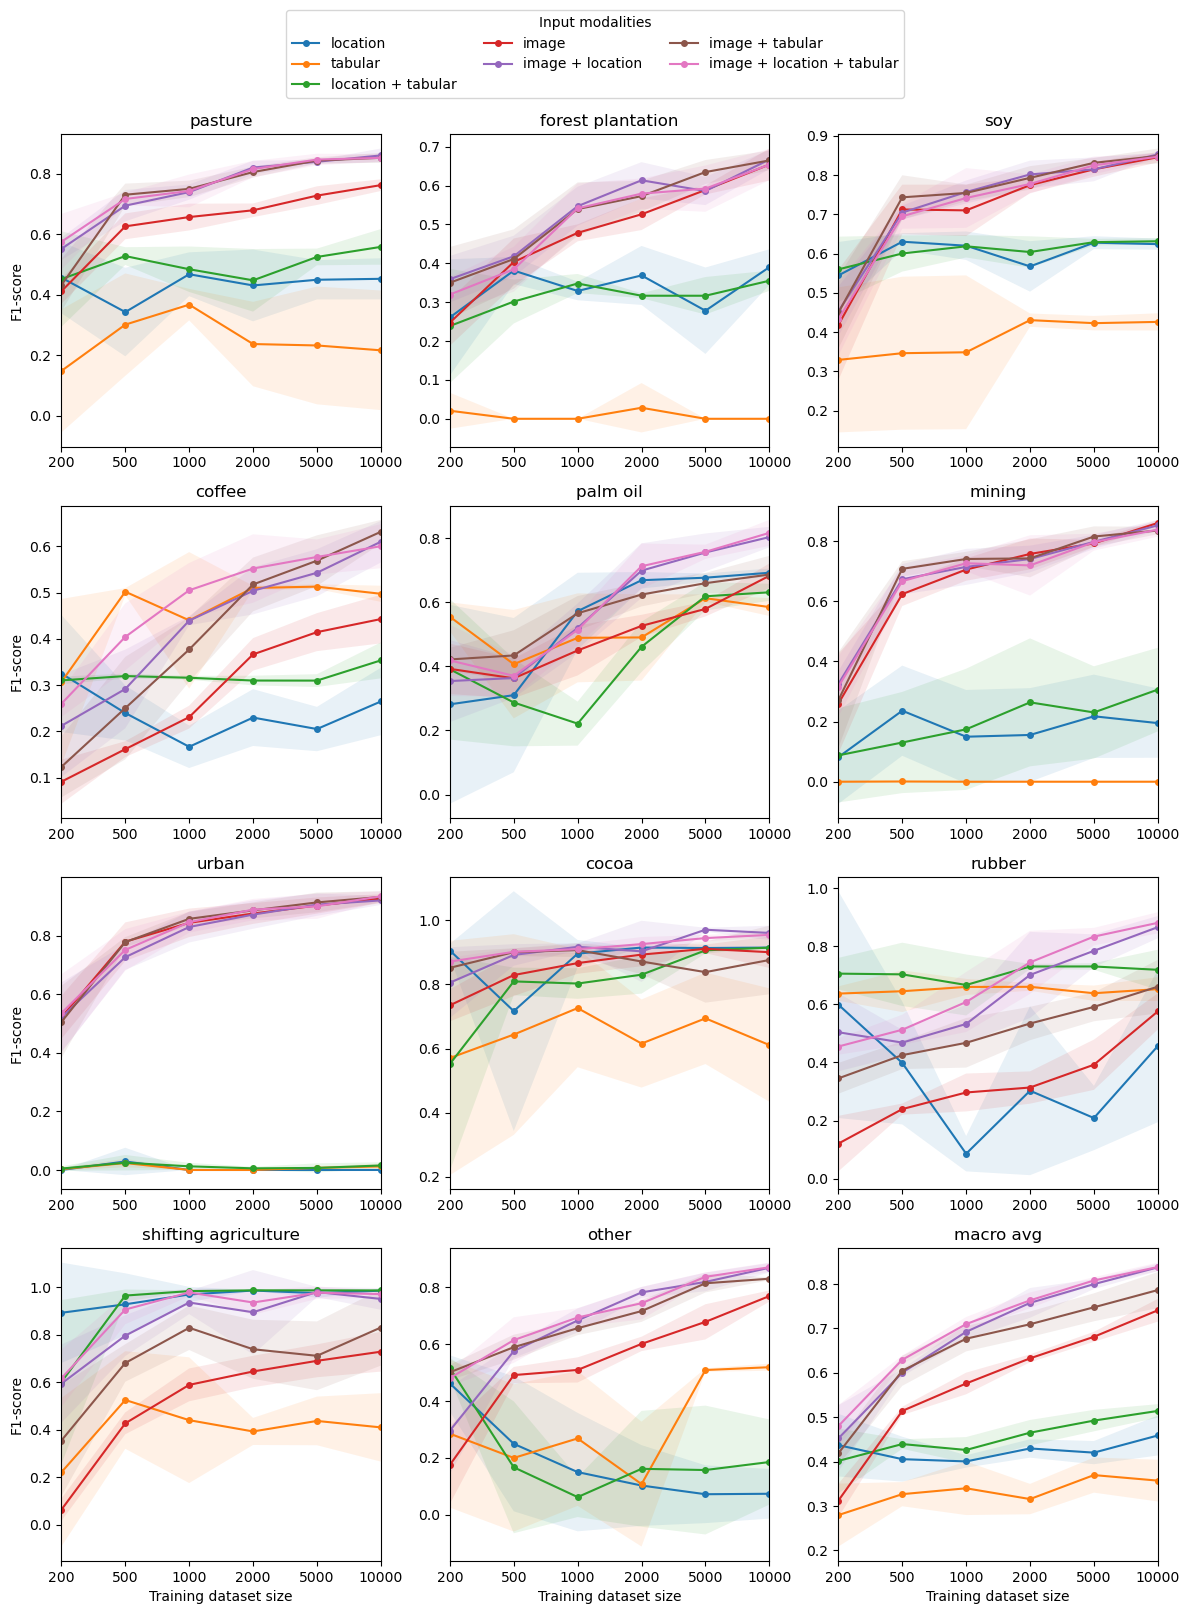

In [56]:
x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]
x_indices = range(len(x_axis_vals))

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

# Track unique labels for the global legend
unique_labels = {}

_idx = 0
for i in range(4):
    for j in range(3):
        try:
            _cls = list(LABEL_MAPPING.keys())[_idx]
        except IndexError:
            _cls = 'macro avg'
        

        cls_stats = process_stats_all(performance_per_configuration_renamed, _cls, n_examples_list=x_axis_vals)
        for key, value in cls_stats.items():
            #if not "'image_encoder': {'use': True}" in key:
            #    continue
            acc = value['acc']
            std = value['std']

            # Plot each line on the current subplot
            line, = axes[i, j].plot(x_indices, acc, marker='o',markersize=4, label=run_names_mapping[key])
            axes[i, j].fill_between(x_indices, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1)

            # Store only unique labels for global legend
            if run_names_mapping[key] not in unique_labels:
                unique_labels[run_names_mapping[key]] = line

        axes[i, j].set_xticks(x_indices)
        axes[i, j].set_xticklabels(x_axis_vals)
        #axes[i, j].set_ylim(0, 1)
        axes[i, j].set_xlim(0, len(x_indices) - 1)
        axes[i, j].set_title(_cls)
        if _idx in [0,3,6,9]:
            axes[i, j].set_ylabel('F1-score')
        if _idx in [9,10,11,12]:
            axes[i, j].set_xlabel('Training dataset size')
            
        _idx += 1
        

# Add a global legend with unique labels
fig.legend(unique_labels.values(), unique_labels.keys(), loc='upper center', title='Input modalities', bbox_to_anchor=(0.5, 1.01), ncol=3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
#plt.show()
plt.savefig('../paper/modality_comparison_per_class.png', dpi=200, bbox_inches='tight')


In [49]:
print(list(cls_stats.keys()))

["{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}", "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}", "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}", "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}", "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}", "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}", "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}"]


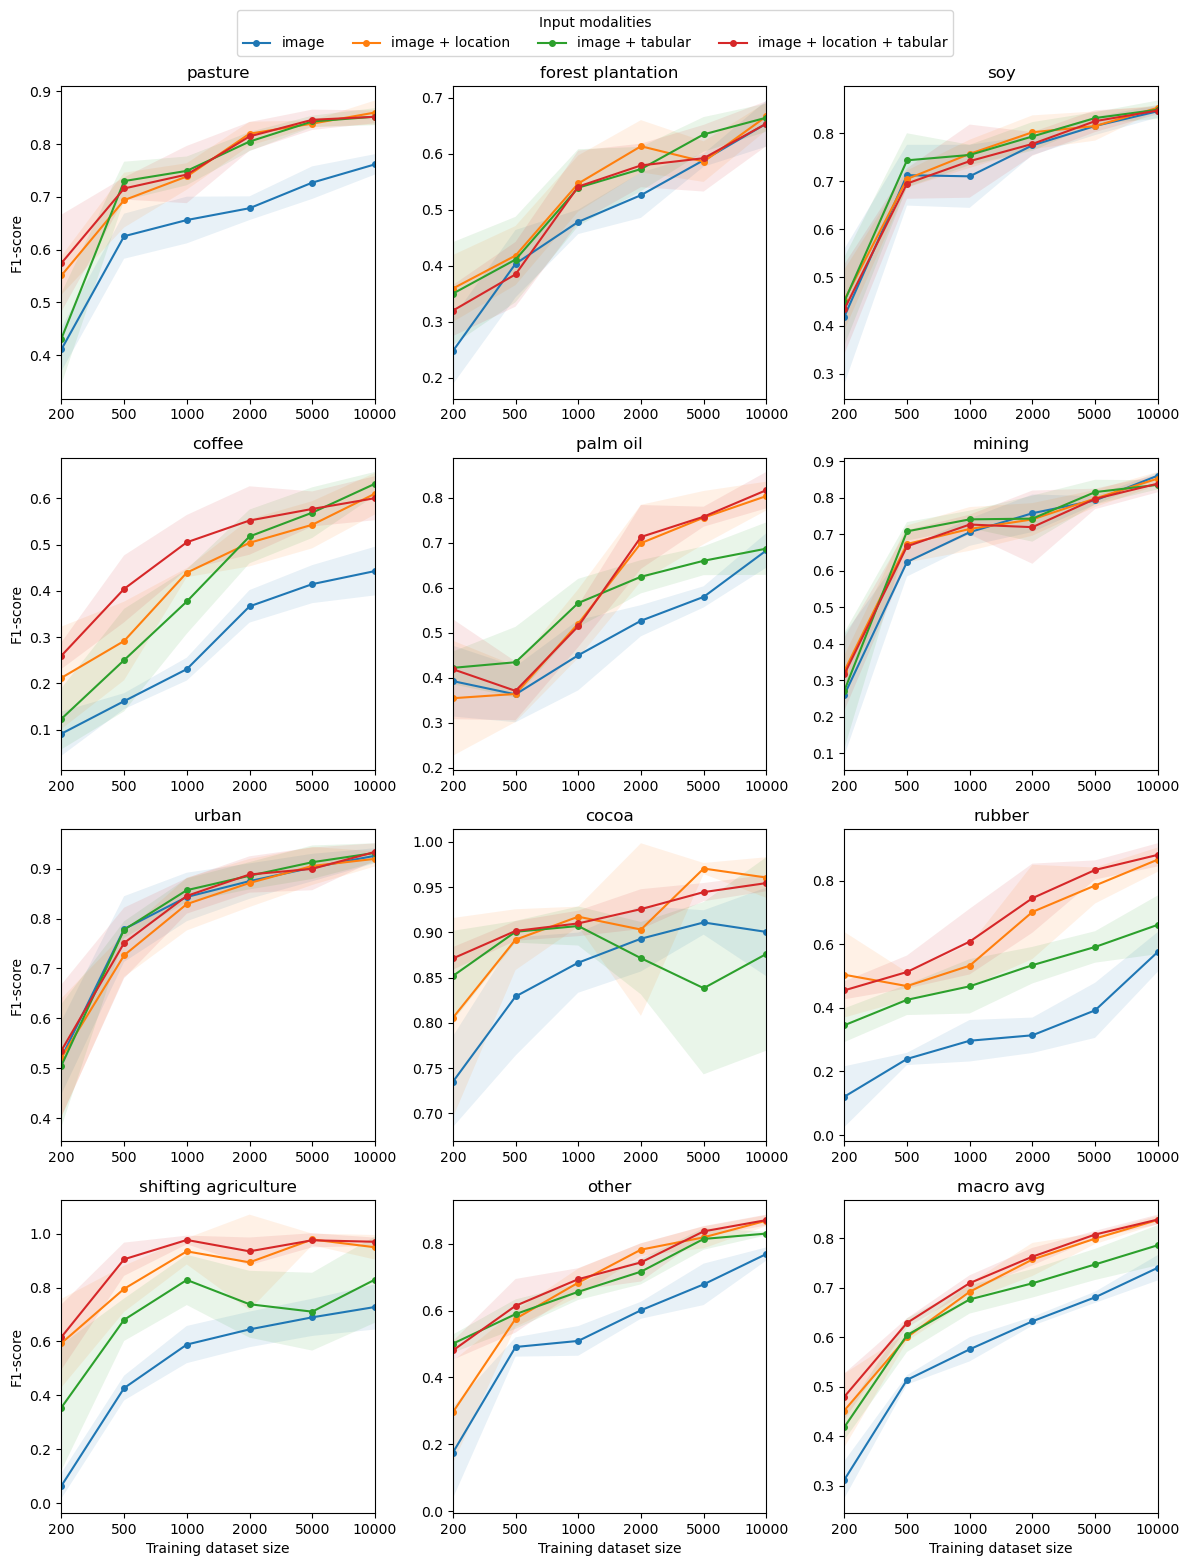

In [55]:
x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]
x_indices = range(len(x_axis_vals))

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

# Track unique labels for the global legend
unique_labels = {}

_idx = 0
for i in range(4):
    for j in range(3):
        try:
            _cls = list(LABEL_MAPPING.keys())[_idx]
        except IndexError:
            _cls = 'macro avg'
        

        cls_stats = process_stats_all(performance_per_configuration_renamed, _cls, n_examples_list=x_axis_vals)
        for key, value in cls_stats.items():
            if not "'image_encoder': {'use': True}" in key:
                continue
            acc = value['acc']
            std = value['std']

            # Plot each line on the current subplot
            line, = axes[i, j].plot(x_indices, acc, marker='o',markersize=4, label=run_names_mapping[key])
            axes[i, j].fill_between(x_indices, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1)

            # Store only unique labels for global legend
            if run_names_mapping[key] not in unique_labels:
                unique_labels[run_names_mapping[key]] = line

        axes[i, j].set_xticks(x_indices)
        axes[i, j].set_xticklabels(x_axis_vals)
        #axes[i, j].set_ylim(0, 1)
        axes[i, j].set_xlim(0, len(x_indices) - 1)
        axes[i, j].set_title(_cls)
        if _idx in [0,3,6,9]:
            axes[i, j].set_ylabel('F1-score')
        if _idx in [9,10,11,12]:
            axes[i, j].set_xlabel('Training dataset size')
            
        _idx += 1
        

# Add a global legend with unique labels
fig.legend(unique_labels.values(), unique_labels.keys(), loc='upper center', title='Input modalities', bbox_to_anchor=(0.5, 0.98), ncol=4)

plt.tight_layout(rect=[0, 0, 1, 0.95])
#plt.show()
plt.savefig('../paper/modality_comparison_per_class_img_models_only.png', dpi=200, bbox_inches='tight')
